# Homework 6.2 - Step 10

## Empirical Failure-Mode Analysis

The final task asks whether the method fails because of:

- too few anchors;
- too little text;
- too large or sparse a vocabulary;
- too small a model;
- attention weights that do not correspond to useful context.

This notebook distinguishes:

$$
\boxed{\text{observed failures}}
$$

from

$$
\boxed{\text{plausible but untested hypotheses}}.
$$

The analysis uses the already-fixed 20%-anchor attention architecture as the reference configuration unless a specific factor is being varied.

## Failure-mode design

### Too few anchors

Use the existing 5%, 10%, 20%, and 40% experiments.

### Too little text

Hold the 20% anchor level and selected architecture fixed, but train on:

$$
25\%,\qquad 50\%,\qquad 100\%
$$

of the training glyph sequence.

The 25% and 50% conditions use deterministic training prefixes. This is a controlled data-volume ablation, but it can also reflect which part of the book appears in the prefix; that limitation is documented.

### Large or sparse vocabulary

Do not change the Homework 5.1 tokenizer.

Instead, stratify held-out accuracy by the center glyph's training frequency.

This tests data sparsity associated with the large vocabulary without changing the frozen tokenization.

### Too small a model

Use the completed architecture sweep.

### Attention does not correspond to useful context

Use the Step 9 intervention results.

A larger perturbation from high-attention replacement than from a low-attention control is evidence that the weights correlate with useful context, but it is not proof of a complete causal explanation.

In [1]:
from pathlib import Path
import json
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw6_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw6_2"
MODEL_DIR = DATA_DIR / "failure_mode_models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

manifest = json.loads(
    (
        DATA_DIR
        / "task2_frozen_information_manifest.json"
    ).read_text(
        encoding="utf-8"
    )
)

selection = json.loads(
    (
        DATA_DIR
        / "task6_selected_attention_architecture.json"
    ).read_text(
        encoding="utf-8"
    )
)

CONFIG = selection[
    "selected_config"
]

K = int(
    manifest["source_vocabulary_size"]
)

ANALYSIS_LEVEL = "20"
SEED = 63870
BATCH_SIZE = 256
MAX_EPOCHS = 8
PATIENCE = 2
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 1e-5
DROPOUT = 0.10

TRAINING_FRACTIONS = [
    0.25,
    0.50,
    1.00,
]

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Selected configuration:")
print(json.dumps(CONFIG, indent=2))
print("Device:", DEVICE)

Selected configuration:
{
  "embed_dim": 96,
  "radius": 4,
  "num_heads": 2,
  "num_layers": 1
}
Device: cuda


# Load the frozen bijective experiment

In [2]:
def absolute_from_manifest(relative_path):
    normalized = str(relative_path).replace("\\", "/")
    return PROJECT_ROOT / Path(normalized)


def pick_column(frame, candidates, label):
    lowered = {
        column.lower(): column
        for column in frame.columns
    }

    for candidate in candidates:
        if candidate.lower() in lowered:
            return lowered[candidate.lower()]

    for column in frame.columns:
        low = column.lower()

        if any(
            candidate.lower() in low
            for candidate in candidates
        ):
            return column

    raise KeyError(
        f"Could not identify {label}. "
        f"Available columns: {list(frame.columns)}"
    )


GLYPH_CANDIDATES = [
    "glyph_id",
    "glyph",
    "glyph_index",
    "token",
]

SOURCE_CANDIDATES = [
    "source_token_id",
    "syllable_id",
    "source_id",
    "token_id",
]


def load_raw_split(split_name):
    frame = pd.read_csv(
        absolute_from_manifest(
            manifest["splits"][
                split_name
            ]
        )
    )

    glyph_col = pick_column(
        frame,
        GLYPH_CANDIDATES,
        "glyph ID",
    )

    return frame[
        glyph_col
    ].to_numpy()


train_raw = load_raw_split(
    "train"
)

validation_raw = load_raw_split(
    "validation"
)

test_raw = load_raw_split(
    "test"
)

pseudo_20 = pd.read_csv(
    absolute_from_manifest(
        manifest[
            "pseudo_label_maps"
        ][ANALYSIS_LEVEL]
    )
)

raw_glyph_ids = np.array(
    sorted(
        pseudo_20[
            "glyph_id"
        ].unique()
    )
)

raw_source_ids = np.array(
    sorted(
        pseudo_20[
            "source_token_id"
        ].unique()
    )
)

glyph_to_index = {
    raw_id: index
    for index, raw_id
    in enumerate(raw_glyph_ids)
}

source_to_index = {
    raw_id: index
    for index, raw_id
    in enumerate(raw_source_ids)
}

index_to_source = {
    index: raw_id
    for raw_id, index
    in source_to_index.items()
}

pseudo_map = dict(
    zip(
        pseudo_20[
            "glyph_id"
        ],
        pseudo_20[
            "source_token_id"
        ],
    )
)


def encode_glyphs(raw_sequence):
    return np.array(
        [
            glyph_to_index[
                glyph
            ]
            for glyph
            in raw_sequence
        ],
        dtype=np.int64,
    )


def pseudo_labels(raw_sequence):
    return np.array(
        [
            source_to_index[
                pseudo_map[
                    glyph
                ]
            ]
            for glyph
            in raw_sequence
        ],
        dtype=np.int64,
    )


train_glyphs = encode_glyphs(
    train_raw
)

validation_glyphs = encode_glyphs(
    validation_raw
)

test_glyphs = encode_glyphs(
    test_raw
)

train_labels = pseudo_labels(
    train_raw
)

validation_labels = pseudo_labels(
    validation_raw
)

common_positions = pd.read_csv(
    absolute_from_manifest(
        manifest[
            "common_evaluation_positions"
        ]
    )
)

validation_positions = (
    common_positions[
        common_positions["split"]
        == "validation"
    ]["position"]
    .to_numpy(dtype=int)
)

test_positions = (
    common_positions[
        common_positions["split"]
        == "test"
    ]["position"]
    .to_numpy(dtype=int)
)

hidden_map = pd.read_csv(
    absolute_from_manifest(
        manifest[
            "evaluation_only_hidden_map"
        ]
    )
)

hidden_glyph_col = pick_column(
    hidden_map,
    GLYPH_CANDIDATES,
    "hidden-map glyph ID",
)

hidden_source_col = pick_column(
    hidden_map,
    SOURCE_CANDIDATES,
    "hidden-map source-token ID",
)

true_inverse_map = dict(
    zip(
        hidden_map[
            hidden_glyph_col
        ],
        hidden_map[
            hidden_source_col
        ],
    )
)

test_true_raw_source = np.array(
    [
        true_inverse_map[
            glyph
        ]
        for glyph in test_raw
    ]
)

test_true_labels = np.array(
    [
        source_to_index[
            source
        ]
        for source
        in test_true_raw_source
    ],
    dtype=np.int64,
)

# Model definition

In [3]:
class CenteredWindowDataset(Dataset):
    def __init__(
        self,
        glyphs,
        labels,
        radius,
        centers,
    ):
        self.glyphs = np.asarray(
            glyphs,
            dtype=np.int64,
        )

        self.labels = np.asarray(
            labels,
            dtype=np.int64,
        )

        self.radius = int(radius)

        centers = np.asarray(
            centers,
            dtype=int,
        )

        valid = (
            (centers >= radius)
            & (
                centers
                < len(glyphs)
                - radius
            )
        )

        self.centers = centers[
            valid
        ]

    def __len__(self):
        return len(self.centers)

    def __getitem__(self, item):
        center = int(
            self.centers[item]
        )

        window = self.glyphs[
            center-self.radius:
            center+self.radius+1
        ]

        return (
            torch.as_tensor(
                window,
                dtype=torch.long,
            ),
            torch.tensor(
                int(
                    self.labels[
                        center
                    ]
                ),
                dtype=torch.long,
            ),
            torch.tensor(
                center,
                dtype=torch.long,
            ),
        )


class AttentionBlock(nn.Module):
    def __init__(
        self,
        embed_dim,
        num_heads,
        dropout,
    ):
        super().__init__()

        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True,
        )

        self.norm1 = nn.LayerNorm(
            embed_dim
        )

        self.feed_forward = nn.Sequential(
            nn.Linear(
                embed_dim,
                2 * embed_dim,
            ),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(
                2 * embed_dim,
                embed_dim,
            ),
        )

        self.norm2 = nn.LayerNorm(
            embed_dim
        )

        self.dropout = nn.Dropout(
            dropout
        )

    def forward(self, x):
        attended, _ = (
            self.attention(
                x,
                x,
                x,
                need_weights=False,
            )
        )

        x = self.norm1(
            x
            + self.dropout(
                attended
            )
        )

        x = self.norm2(
            x
            + self.dropout(
                self.feed_forward(x)
            )
        )

        return x


class CenteredAttentionDecoder(nn.Module):
    def __init__(
        self,
        glyph_vocab_size,
        source_vocab_size,
        radius,
        embed_dim,
        num_heads,
        num_layers,
        dropout,
    ):
        super().__init__()

        self.radius = int(radius)

        self.embedding = nn.Embedding(
            glyph_vocab_size,
            embed_dim,
        )

        self.position_embedding = nn.Embedding(
            2 * self.radius + 1,
            embed_dim,
        )

        self.blocks = nn.ModuleList([
            AttentionBlock(
                embed_dim,
                num_heads,
                dropout,
            )
            for _ in range(
                num_layers
            )
        ])

        self.output = nn.Linear(
            embed_dim,
            source_vocab_size,
        )

    def forward(self, windows):
        positions = torch.arange(
            windows.shape[1],
            device=windows.device,
        )

        x = (
            self.embedding(
                windows
            )
            + self.position_embedding(
                positions
            )[None, :, :]
        )

        for block in self.blocks:
            x = block(x)

        return self.output(
            x[:, self.radius, :]
        )


def build_attention_model():
    return CenteredAttentionDecoder(
        glyph_vocab_size=K,
        source_vocab_size=K,
        radius=int(
            CONFIG["radius"]
        ),
        embed_dim=int(
            CONFIG["embed_dim"]
        ),
        num_heads=int(
            CONFIG["num_heads"]
        ),
        num_layers=int(
            CONFIG["num_layers"]
        ),
        dropout=DROPOUT,
    )

# Failure mode 1: too few anchors

This factor is already directly tested by the 5%, 10%, 20%, and 40% experiments.

In [4]:
bijective_results = pd.read_csv(
    DATA_DIR
    / "task5_bijective_decoder_comparison.csv"
)

ambiguous_results = pd.read_csv(
    DATA_DIR
    / "task7_ambiguous_decoder_comparison.csv"
)

anchor_attention = (
    bijective_results[
        bijective_results[
            "model"
        ] == "attention"
    ]
    .sort_values(
        "anchor_level"
    )
)

print(
    anchor_attention[
        [
            "anchor_level",
            "overall_accuracy",
            "unanchored_accuracy",
            "all_K_map_recovery",
        ]
    ].to_string(
        index=False
    )
)

 anchor_level  overall_accuracy  unanchored_accuracy  all_K_map_recovery
            5          0.089297             0.036199            0.024246
           10          0.163797             0.077651            0.045216
           20          0.267976             0.093562            0.079292
           40          0.454270             0.157118            0.158912


# Failure mode 2: too little training text

The selected 20%-anchor attention architecture is trained on deterministic prefixes containing 25%, 50%, and 100% of the available training glyph sequence.

All models use the full validation split for early stopping.

The held-out truth evaluation is performed only after each model's validation-best checkpoint is fixed.

In [5]:
RADIUS = int(
    CONFIG["radius"]
)


def train_fraction_model(
    fraction,
    run_seed,
):
    usable_length = int(
        len(train_glyphs)
        * fraction
    )

    training_centers = np.arange(
        RADIUS,
        usable_length - RADIUS,
        dtype=int,
    )

    train_dataset = CenteredWindowDataset(
        train_glyphs,
        train_labels,
        radius=RADIUS,
        centers=training_centers,
    )

    validation_dataset = CenteredWindowDataset(
        validation_glyphs,
        validation_labels,
        radius=RADIUS,
        centers=validation_positions,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    random.seed(run_seed)
    np.random.seed(run_seed)
    torch.manual_seed(run_seed)

    model = build_attention_model().to(
        DEVICE
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    loss_fn = nn.CrossEntropyLoss()

    best_nll = float("inf")
    best_state = None
    best_epoch = None
    stale = 0

    for epoch in range(
        1,
        MAX_EPOCHS + 1,
    ):
        model.train()

        for windows, labels, _ in train_loader:
            windows = windows.to(
                DEVICE
            )

            labels = labels.to(
                DEVICE
            )

            optimizer.zero_grad()

            loss = loss_fn(
                model(windows),
                labels,
            )

            loss.backward()
            optimizer.step()

        model.eval()

        total_loss = 0.0
        total = 0

        with torch.no_grad():
            for windows, labels, _ in validation_loader:
                windows = windows.to(
                    DEVICE
                )

                labels = labels.to(
                    DEVICE
                )

                logits = model(
                    windows
                )

                total_loss += float(
                    nn.functional.cross_entropy(
                        logits,
                        labels,
                        reduction="sum",
                    ).item()
                )

                total += int(
                    labels.shape[0]
                )

        validation_nll = (
            total_loss / total
        )

        if (
            validation_nll
            < best_nll - 1e-6
        ):
            best_nll = (
                validation_nll
            )

            best_epoch = epoch

            best_state = {
                key: value.detach()
                .cpu()
                .clone()
                for key, value
                in model.state_dict().items()
            }

            stale = 0

        else:
            stale += 1

        if stale >= PATIENCE:
            break

    model.load_state_dict(
        best_state
    )

    checkpoint_path = (
        MODEL_DIR
        / (
            "attention_text_fraction_"
            f"{int(100*fraction):03d}.pt"
        )
    )

    torch.save(
        {
            "state_dict": best_state,
            "fraction": fraction,
            "best_epoch": best_epoch,
            "validation_nll": best_nll,
            "config": CONFIG,
        },
        checkpoint_path,
    )

    return (
        model,
        {
            "training_fraction": (
                fraction
            ),
            "training_glyphs_used": (
                usable_length
            ),
            "training_windows": (
                len(training_centers)
            ),
            "best_epoch": (
                best_epoch
            ),
            "validation_nll": (
                best_nll
            ),
            "checkpoint": str(
                checkpoint_path.relative_to(
                    PROJECT_ROOT
                )
            ),
        },
    )


def evaluate_truth(
    model,
):
    dummy = np.zeros(
        len(test_glyphs),
        dtype=np.int64,
    )

    dataset = CenteredWindowDataset(
        test_glyphs,
        dummy,
        radius=RADIUS,
        centers=test_positions,
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    anchored_set = set(
        pd.read_csv(
            absolute_from_manifest(
                manifest["anchors"][
                    ANALYSIS_LEVEL
                ]
            )
        )[
            pick_column(
                pd.read_csv(
                    absolute_from_manifest(
                        manifest["anchors"][
                            ANALYSIS_LEVEL
                        ]
                    )
                ),
                GLYPH_CANDIDATES,
                "glyph ID",
            )
        ].tolist()
    )

    rows = []

    model.eval()

    with torch.no_grad():
        for windows, _, centers_batch in loader:
            windows = windows.to(
                DEVICE
            )

            logits = model(
                windows
            )

            predicted = logits.argmax(
                dim=1
            ).cpu().numpy()

            for center, pred in zip(
                centers_batch.numpy(),
                predicted,
            ):
                center = int(center)

                rows.append({
                    "position": center,
                    "anchored": (
                        test_raw[
                            center
                        ]
                        in anchored_set
                    ),
                    "correct": (
                        int(pred)
                        == int(
                            test_true_labels[
                                center
                            ]
                        )
                    ),
                })

    frame = pd.DataFrame(rows)

    unanchored = frame[
        ~frame["anchored"]
    ]

    return {
        "overall_test_accuracy": float(
            frame["correct"].mean()
        ),
        "unanchored_test_accuracy": float(
            unanchored[
                "correct"
            ].mean()
        ),
        "evaluated_positions": len(
            frame
        ),
    }

In [6]:
text_fraction_records = []

for index, fraction in enumerate(
    TRAINING_FRACTIONS
):
    model, record = (
        train_fraction_model(
            fraction,
            run_seed=(
                SEED
                + index
            ),
        )
    )

    truth_metrics = (
        evaluate_truth(
            model
        )
    )

    text_fraction_records.append({
        **record,
        **truth_metrics,
    })


text_fraction_results = (
    pd.DataFrame(
        text_fraction_records
    )
)

text_fraction_path = (
    DATA_DIR
    / "task10_training_text_ablation.csv"
)

text_fraction_results.to_csv(
    text_fraction_path,
    index=False,
)

print(
    text_fraction_results.to_string(
        index=False
    )
)

 training_fraction  training_glyphs_used  training_windows  best_epoch  validation_nll                                                    checkpoint  overall_test_accuracy  unanchored_test_accuracy  evaluated_positions
              0.25                 13520             13512           7        0.539880 data\hw6_2\failure_mode_models\attention_text_fraction_025.pt               0.262525                  0.093562                11557
              0.50                 27041             27033           5        0.323335 data\hw6_2\failure_mode_models\attention_text_fraction_050.pt               0.265640                  0.093562                11557
              1.00                 54082             54074           4        0.195189 data\hw6_2\failure_mode_models\attention_text_fraction_100.pt               0.267976                  0.093562                11557


## Training-text ablation plot

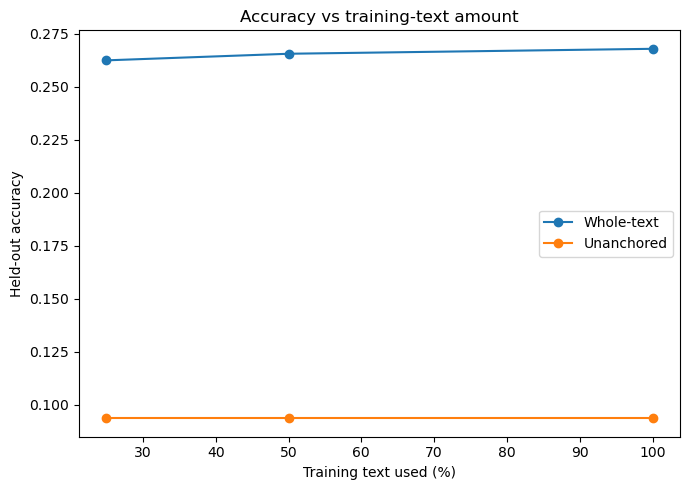

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.2\result images\hw6_2\task10_accuracy_vs_training_text.png


In [7]:
plt.figure(figsize=(7, 5))

plt.plot(
    100
    * text_fraction_results[
        "training_fraction"
    ],
    text_fraction_results[
        "overall_test_accuracy"
    ],
    marker="o",
    label="Whole-text",
)

plt.plot(
    100
    * text_fraction_results[
        "training_fraction"
    ],
    text_fraction_results[
        "unanchored_test_accuracy"
    ],
    marker="o",
    label="Unanchored",
)

plt.xlabel(
    "Training text used (%)"
)
plt.ylabel("Held-out accuracy")
plt.title(
    "Accuracy vs training-text amount"
)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "task10_accuracy_vs_training_text.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

# Failure mode 3: large / sparse vocabulary

The vocabulary itself remains frozen.

Instead, held-out prediction accuracy is stratified by the original glyph's frequency in the training sequence.

Frequency quartiles are computed across glyph **types**, not across occurrences.

In [8]:
prediction_20 = pd.read_csv(
    DATA_DIR
    / "task5_predictions_attention_anchors_20.csv"
)

training_frequency = (
    pd.Series(train_raw)
    .value_counts()
)

type_frequencies = np.array([
    training_frequency.get(
        glyph,
        0,
    )
    for glyph in raw_glyph_ids
])

q1, q2, q3 = np.quantile(
    type_frequencies,
    [
        0.25,
        0.50,
        0.75,
    ],
)


def frequency_band(count):
    if count <= q1:
        return "Q1_lowest_frequency"

    if count <= q2:
        return "Q2"

    if count <= q3:
        return "Q3"

    return "Q4_highest_frequency"


prediction_20[
    "training_glyph_frequency"
] = [
    int(
        training_frequency.get(
            glyph,
            0,
        )
    )
    for glyph
    in prediction_20[
        "center_glyph_id"
    ]
]

prediction_20[
    "frequency_band"
] = [
    frequency_band(count)
    for count
    in prediction_20[
        "training_glyph_frequency"
    ]
]

frequency_results = (
    prediction_20
    .groupby(
        "frequency_band",
        sort=False,
    )
    .agg(
        evaluated_occurrences=(
            "correct",
            "size",
        ),
        accuracy=(
            "correct",
            "mean",
        ),
        mean_training_frequency=(
            "training_glyph_frequency",
            "mean",
        ),
    )
    .reset_index()
)

frequency_path = (
    DATA_DIR
    / "task10_accuracy_by_training_frequency.csv"
)

frequency_results.to_csv(
    frequency_path,
    index=False,
)

print(
    "Type-frequency quartile cut points:",
    q1,
    q2,
    q3,
)

print()
print(
    frequency_results.to_string(
        index=False
    )
)

Type-frequency quartile cut points: 1.0 2.0 6.0

      frequency_band  evaluated_occurrences  accuracy  mean_training_frequency
Q4_highest_frequency                  10594  0.279215               466.271380
                  Q3                    421  0.190024                 4.432304
 Q1_lowest_frequency                    416  0.084135                 0.411058
                  Q2                    126  0.190476                 2.000000


## Unanchored frequency diagnostic

The overall frequency table mixes anchored and unanchored occurrences. Because anchored glyphs are much easier by construction, that can exaggerate the apparent effect of training frequency.

To diagnose the sparse-vocabulary failure mode more cleanly, the same frequency bands are recomputed **only on unanchored test occurrences**. This does not make frequency causal, but it removes the most direct anchor-status confound.

In [9]:
unanchored_prediction_20 = prediction_20[
    ~prediction_20["anchored"]
].copy()

unanchored_frequency_results = (
    unanchored_prediction_20
    .groupby(
        "frequency_band",
        sort=False,
    )
    .agg(
        evaluated_unanchored_occurrences=(
            "correct",
            "size",
        ),
        unanchored_accuracy=(
            "correct",
            "mean",
        ),
        mean_training_frequency=(
            "training_glyph_frequency",
            "mean",
        ),
    )
    .reset_index()
)

unanchored_frequency_path = (
    DATA_DIR
    / "task10_unanchored_accuracy_by_training_frequency.csv"
)

unanchored_frequency_results.to_csv(
    unanchored_frequency_path,
    index=False,
)

print(
    unanchored_frequency_results.to_string(
        index=False
    )
)


      frequency_band  evaluated_unanchored_occurrences  unanchored_accuracy  mean_training_frequency
                  Q3                               341             0.000000                 4.486804
Q4_highest_frequency                              8505             0.102175               466.610582
 Q1_lowest_frequency                               340             0.000000                 0.400000
                  Q2                               102             0.000000                 2.000000


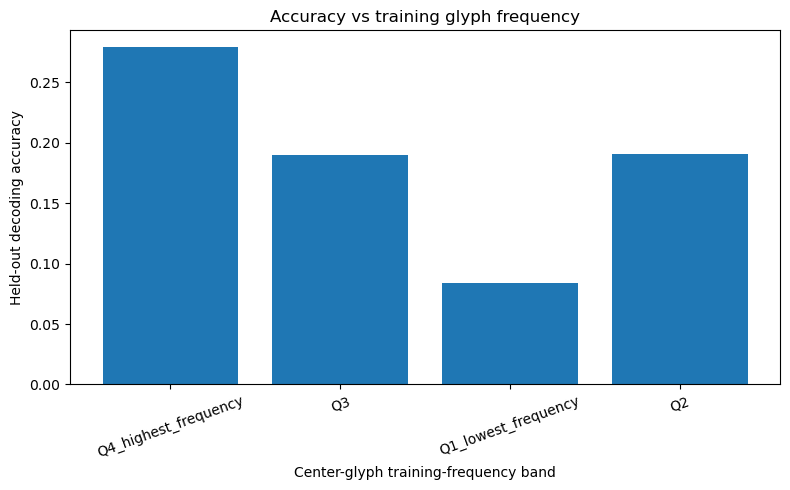

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.2\result images\hw6_2\task10_accuracy_by_glyph_frequency.png


In [10]:
plt.figure(figsize=(8, 5))

plt.bar(
    frequency_results[
        "frequency_band"
    ],
    frequency_results[
        "accuracy"
    ],
)

plt.xlabel(
    "Center-glyph training-frequency band"
)
plt.ylabel(
    "Held-out decoding accuracy"
)
plt.title(
    "Accuracy vs training glyph frequency"
)
plt.xticks(rotation=20)
plt.tight_layout()

path = (
    RESULT_DIR
    / "task10_accuracy_by_glyph_frequency.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

# Failure mode 4: too small a model

The architecture sweep already varies:

- embedding dimension;
- context radius;
- attention heads;
- attention layers.

Parameter count is compared with validation pseudo-label NLL.

Because architecture changes more than parameter count alone, this is evidence about the tested architectures rather than a theorem that parameter count causes performance.

In [11]:
architecture_results = pd.read_csv(
    DATA_DIR
    / "task6_architecture_sweep.csv"
)

parameter_spearman = (
    architecture_results[
        [
            "trainable_parameters",
            "validation_nll",
        ]
    ]
    .corr(
        method="spearman"
    )
    .iloc[
        0,
        1,
    ]
)

print(
    architecture_results[
        [
            "name",
            "trainable_parameters",
            "validation_nll",
            "validation_accuracy",
        ]
    ]
    .sort_values(
        "trainable_parameters"
    )
    .to_string(
        index=False
    )
)

print()
print(
    "Spearman correlation between parameter count "
    "and validation NLL:",
    parameter_spearman,
)

     name  trainable_parameters  validation_nll  validation_accuracy
 embed_32                207212        0.238195             0.980272
 radius_2                427500        0.205740             0.980272
reference                427756        0.206564             0.980272
  heads_1                427756        0.204591             0.980272
  heads_4                427756        0.207798             0.980272
 radius_8                428268        0.205718             0.980272
radius_16                429292        0.206489             0.980272
 layers_2                461228        0.206750             0.980272
 embed_96                664684        0.196854             0.980272

Spearman correlation between parameter count and validation NLL: -0.44074127735352675


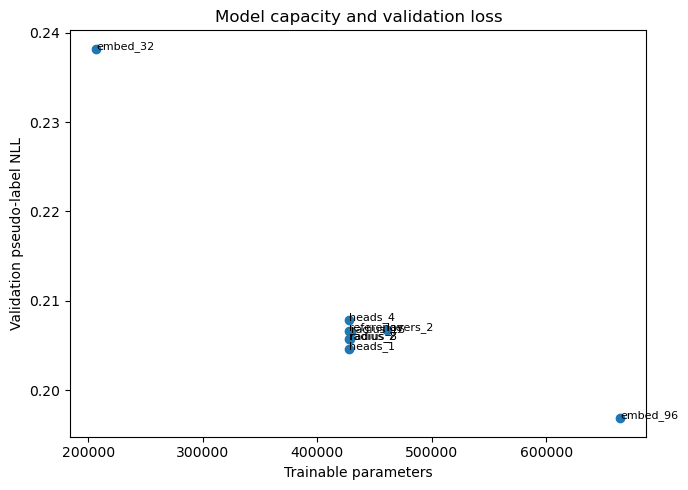

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.2\result images\hw6_2\task10_model_capacity_vs_validation_nll.png


In [12]:
plt.figure(figsize=(7, 5))

plt.scatter(
    architecture_results[
        "trainable_parameters"
    ],
    architecture_results[
        "validation_nll"
    ],
)

for row in architecture_results.itertuples():
    plt.annotate(
        row.name,
        (
            row.trainable_parameters,
            row.validation_nll,
        ),
        fontsize=8,
    )

plt.xlabel(
    "Trainable parameters"
)
plt.ylabel(
    "Validation pseudo-label NLL"
)
plt.title(
    "Model capacity and validation loss"
)
plt.tight_layout()

path = (
    RESULT_DIR
    / "task10_model_capacity_vs_validation_nll.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

# Failure mode 5: attention weights may not correspond to useful context

The Step 9 intervention summary is the direct test.

The key comparison is:

$$
\text{high-attention replacement}
\quad\text{vs}\quad
\text{low-attention replacement}.
$$

If high-attention replacement produces a larger output perturbation, the weights contain some information about influential context.

If the effects are similar, interpreting large weights as importance is weak.

In [13]:
intervention_summary_path = (
    DATA_DIR
    / "task9_context_intervention_summary.csv"
)

if intervention_summary_path.exists():
    intervention_summary = pd.read_csv(
        intervention_summary_path
    )

    print(
        intervention_summary.to_string(
            index=False
        )
    )

else:
    intervention_summary = None

    print(
        "Step 9 intervention results are not yet available. "
        "Run the intervention stage after recording the LLM response."
    )

          Unnamed: 0                Unnamed: 1 true_probability_drop true_probability_drop.1 true_probability_drop.2 true_probability_drop.3 absolute_true_probability_change absolute_true_probability_change.1 absolute_true_probability_change.2 absolute_true_probability_change.3 prediction_changed prediction_changed.1 prediction_changed.2 prediction_changed.3
                 NaN                       NaN                 count                    mean                  median                     std                            count                               mean                             median                                std              count                 mean               median                  std
ambiguous_occurrence              intervention                   NaN                     NaN                     NaN                     NaN                              NaN                                NaN                                NaN                                NaN

# Synthesis table

The code below creates a compact evidence table.

The table does not turn partial evidence into stronger causal claims.

In [14]:
failure_rows = []

# Anchors.
anchor_low = (
    anchor_attention.iloc[0]
)

anchor_high = (
    anchor_attention.iloc[-1]
)

failure_rows.append({
    "candidate_failure": (
        "too few anchors"
    ),
    "status": (
        "directly tested"
    ),
    "evidence": (
        f"unanchored accuracy changes from "
        f"{anchor_low['unanchored_accuracy']:.4f} "
        f"at {int(anchor_low['anchor_level'])}% anchors "
        f"to {anchor_high['unanchored_accuracy']:.4f} "
        f"at {int(anchor_high['anchor_level'])}% anchors"
    ),
    "interpretation_limit": (
        "anchor level changes supervision directly; "
        "it does not isolate all other identification limits"
    ),
})

# Text amount.
text_low = (
    text_fraction_results
    .sort_values(
        "training_fraction"
    )
    .iloc[0]
)

text_high = (
    text_fraction_results
    .sort_values(
        "training_fraction"
    )
    .iloc[-1]
)

failure_rows.append({
    "candidate_failure": (
        "too little training text"
    ),
    "status": (
        "directly tested with prefix ablation"
    ),
    "evidence": (
        f"overall accuracy changes from "
        f"{text_low['overall_test_accuracy']:.4f} "
        f"at {100*text_low['training_fraction']:.0f}% text "
        f"to {text_high['overall_test_accuracy']:.4f} "
        f"at {100*text_high['training_fraction']:.0f}% text"
    ),
    "interpretation_limit": (
        "prefix ablation also changes which text is observed, "
        "not only the number of tokens"
    ),
})

# Vocabulary sparsity.
ordered_frequency = (
    frequency_results
    .set_index(
        "frequency_band"
    )
)

low_frequency_accuracy = float(
    ordered_frequency.loc[
        "Q1_lowest_frequency",
        "accuracy",
    ]
)

high_frequency_accuracy = float(
    ordered_frequency.loc[
        "Q4_highest_frequency",
        "accuracy",
    ]
)

failure_rows.append({
    "candidate_failure": (
        "large / sparse vocabulary"
    ),
    "status": (
        "partially tested through training-frequency stratification"
    ),
    "evidence": (
        f"lowest-frequency quartile accuracy={low_frequency_accuracy:.4f}; "
        f"highest-frequency quartile accuracy={high_frequency_accuracy:.4f}"
    ),
    "interpretation_limit": (
        "frequency association does not prove vocabulary size itself is causal"
    ),
})

# Capacity.
best_arch = (
    architecture_results
    .sort_values(
        "validation_nll"
    )
    .iloc[0]
)

failure_rows.append({
    "candidate_failure": (
        "model too small"
    ),
    "status": (
        "directly varied across tested architectures"
    ),
    "evidence": (
        f"best tested validation NLL={best_arch['validation_nll']:.4f} "
        f"with {int(best_arch['trainable_parameters']):,} parameters; "
        f"parameter/NLL Spearman correlation={parameter_spearman:.3f}"
    ),
    "interpretation_limit": (
        "architecture, context, and parameter count vary together in parts of the sweep"
    ),
})

# Attention usefulness.
if intervention_summary is not None:
    failure_rows.append({
        "candidate_failure": (
            "attention weights do not correspond to useful context"
        ),
        "status": (
            "directly tested with replacement/permutation interventions"
        ),
        "evidence": (
            "see task9_context_intervention_summary.csv for "
            "top-attention, low-attention, and permutation effects"
        ),
        "interpretation_limit": (
            "a local intervention test does not make attention a complete causal explanation"
        ),
    })

else:
    failure_rows.append({
        "candidate_failure": (
            "attention weights do not correspond to useful context"
        ),
        "status": (
            "not yet evaluated"
        ),
        "evidence": (
            "Step 9 intervention stage has not been run"
        ),
        "interpretation_limit": (
            "large weights alone are not evidence of causal importance"
        ),
    })


failure_evidence = pd.DataFrame(
    failure_rows
)

failure_path = (
    DATA_DIR
    / "task10_failure_mode_evidence.csv"
)

failure_evidence.to_csv(
    failure_path,
    index=False,
)

print(
    failure_evidence.to_string(
        index=False
    )
)

                                    candidate_failure                                                     status                                                                                             evidence                                                                           interpretation_limit
                                      too few anchors                                            directly tested                       unanchored accuracy changes from 0.0362 at 5% anchors to 0.1571 at 40% anchors anchor level changes supervision directly; it does not isolate all other identification limits
                             too little training text                       directly tested with prefix ablation                              overall accuracy changes from 0.2625 at 25% text to 0.2680 at 100% text             prefix ablation also changes which text is observed, not only the number of tokens
                            large / sparse vocabulary partially tested th

# Step 10 Final Failure-Mode Critique

The evidence does **not** support all proposed failure explanations equally. The most defensible conclusion is that the main bottleneck is limited supervision/identifiability for unanchored syllable names, amplified by sparse rare glyphs. Too little text and too little model capacity are much weaker explanations in the tested range, and the Step 9 interventions show that the attention mechanism does use informative context for ambiguous symbols.

## 1. Too few anchors - strongly supported as a limitation

This is the clearest manipulated factor. For the attention decoder, unanchored test accuracy rises from

$$
3.62\% \quad\text{at 5\% anchors}
$$

to

$$
15.71\% \quad\text{at 40\% anchors}.
$$

Increasing the anchor set therefore provides substantially more information that improves the Republic-informed pseudo-map and the downstream decoder. However, even at 40% anchors, unanchored accuracy remains low, so anchors alone do not eliminate the identifiability problem.

The causal wording should remain narrow: changing anchor percentage changes both the amount of revealed supervision and the inferred pseudo-label map. It does not isolate every other source of error.

## 2. Too little training text - only weakly supported

The 20%-anchor text ablation gives

$$
26.25\%\rightarrow 26.56\%\rightarrow 26.80\%
$$

overall test accuracy as the usable training text increases from 25% to 50% to 100%.

That is only about a

$$
0.55\text{ percentage-point}
$$

gain from 25% to 100%. More importantly, unanchored true accuracy is

$$
9.356\%
$$

in **all three** conditions. Validation pseudo-label NLL improves substantially with more text, so additional text helps the network imitate the fixed pseudo-label mapping, but it does not improve recovery of the genuinely hidden unanchored names in this experiment.

Therefore "too little text" is not supported as the main explanation for the remaining decipherment error. This ablation also uses deterministic text prefixes and one training seed per condition, so small differences should not be over-interpreted.

## 3. Large / sparse vocabulary - strongly associated with failure, but not isolated causally

The original all-occurrence analysis shows accuracy of about

$$
8.41\%
$$

for the lowest-frequency type quartile and

$$
27.92\%
$$

for the highest-frequency quartile. Because anchored occurrences are easier, the cleaner diagnostic is the unanchored-only table added above:

- Q1 unanchored accuracy: **0.00%** over 340 occurrences;
- Q2 unanchored accuracy: **0.00%** over 102 occurrences;
- Q3 unanchored accuracy: **0.00%** over 341 occurrences;
- Q4 unanchored accuracy: **10.22%** over 8,505 occurrences.

This is strong evidence that rare glyph types are a serious empirical difficulty. It does **not** prove that reducing the vocabulary size itself would solve the problem, because token frequency is correlated with how well the Republic-based pseudo-map can be inferred and with how much supervision each type receives.

## 4. Model too small - not supported as the dominant failure mode

The architecture sweep does show that the larger embedding model gives the best validation pseudo-label NLL:

$$
0.1969
$$

with 664,684 trainable parameters. The Spearman correlation between parameter count and validation NLL is about

$$
-0.441,
$$

so there is some tendency for larger tested models to fit the pseudo-label targets better.

However, validation accuracy is essentially unchanged across the sweep, and increasing heads, layers, or context radius does not give a consistent improvement. More importantly, in the bijective experiment the attention and matched MLP models have exactly the same unanchored truth accuracy at every anchor level. This indicates that the principal limitation is upstream pseudo-label/identifiability error rather than inability of the neural decoder to fit the targets.

Thus the data do not support the claim that a substantially larger attention model would by itself solve the decipherment problem. Because the largest embedding dimension tested also had the best NLL, still larger models cannot be ruled out; they are simply not established as the main bottleneck.

## 5. Attention weights do not correspond to useful context - rejected as a blanket explanation

Step 9 directly tests this claim. For ambiguous occurrences, replacing the highest-attended non-center symbol changes the true-label probability by an average absolute amount of

$$
0.19248,
$$

compared with only

$$
0.00203
$$

for the lowest-attended replacement. The argmax prediction changes in 37.04% versus 0.82% of cases. Permuting all non-center context positions changes 38.07% of ambiguous predictions.

Therefore the attention weights do correspond to **useful, intervention-sensitive context** for ambiguous occurrences in this model. The effect is tiny for unambiguous occurrences, which is exactly what we would expect when the center glyph identity already carries most of the available information.

This does not mean the attention model is globally superior. At 20% anchors, ambiguous-occurrence accuracy is

$$
38.30\%
$$

for attention versus

$$
40.08\%
$$

for the matched MLP. Attention has modest gains at 5% and 10% anchors but loses on several metrics at 20% and 40%. Thus useful attention does not automatically imply better end-to-end decoding accuracy.

## 6. Main failure mechanism

The results point to a hierarchy of limitations:

1. **Insufficient identifying information for unanchored syllable names is the main bottleneck.** The neural models are trained on Republic-informed pseudo-labels. When those pseudo-label identities are wrong, additional neural capacity cannot recover the hidden English name from the glyph sequence alone.
2. **Sparse/rare glyphs make that inference problem worse.** Unanchored rare-frequency bands have essentially zero recovery in the current experiment.
3. **More anchors help substantially** because they add genuine identity information and constrain the pseudo-map.
4. **More training text helps pseudo-label fitting but not unanchored truth recovery** over the tested range.
5. **Attention is genuinely context-sensitive for deliberately ambiguous symbols**, but that local contextual benefit does not consistently beat the matched MLP and does not solve the unrevealed-name identifiability problem.

## Final Step 10 answer

The method is therefore failing primarily because the allowed evidence is insufficient to identify many unanchored syllable names, especially for sparse glyph types—not because the attention mechanism ignores context and not primarily because the model is too small. The controlled ambiguity experiment shows that attention can use surrounding glyphs to distinguish occurrences of a many-to-one symbol. What it cannot do is manufacture missing lexical identity information that is absent from the anchors and imperfect Republic-informed pseudo-label map.

# Step 10 outputs

- `task10_training_text_ablation.csv`
- `task10_accuracy_by_training_frequency.csv`
- `task10_unanchored_accuracy_by_training_frequency.csv` (generated by the added diagnostic cell)
- `task10_failure_mode_evidence.csv`
- `task10_accuracy_vs_training_text.png`
- `task10_accuracy_by_glyph_frequency.png`
- `task10_model_capacity_vs_validation_nll.png`

Together with the Step 9 intervention results, these files support the failure-mode conclusions stated above.